<a href="https://colab.research.google.com/github/katepashchenko/python_test/blob/main/%D0%9A%D0%BE%D0%BF%D1%96%D1%8F_%D0%B7%D0%B0%D0%BF%D0%B8%D1%81%D0%BD%D0%B8%D0%BA%D0%B0_%22HW_11_1_%D0%92%D1%96%D0%B7%D1%83%D0%B0%D0%BB%D1%96%D0%B7%D0%B0%D1%86%D1%96%D1%8F_%D0%B4%D0%B0%D0%BD%D0%B8%D1%85_%D0%B7_Pandas_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Візуалізація даних з Pandas

## Опис завдання
У цьому домашньому завданні ви працюватимете з датасетом про оренду велосипедів `yulu_rental.csv`. Датасет містить інформацію про кількість орендованих велосипедів залежно від погодних умов, сезону та інших факторів.
Набір даних взяти з Kaggle. Посилання на оригінальний [опис](https://www.kaggle.com/datasets/ranitsarkar01/yulu-bike-sharing-data?select=yulu_bike_sharing_dataset.csv).

**Опис колонок:**
- `datetime` - дата та час
- `season` - квартал (1-Q1, 2-Q2, 3-Q3, 4-Q4)
- `holiday` - чи є день святковим (0=ні, 1=так)
- `workingday` - чи є день робочим (0=ні, 1=так)
- `weather` - погодні умови (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ)
- `temp` - температура в градусах Цельсія
- `atemp` - відчувається як температура
- `humidity` - вологість (%)
- `windspeed` - швидкість вітру
- `casual` - кількість випадкових користувачів
- `registered` - кількість зареєстрованих користувачів
- `count` - загальна кількість орендованих велосипедів



---
🌱 Коментар щодо сезонності

Колонка season у датасеті представляє саме квартали року, а не метеорологічні сезони. Тому всі аналізи сезонності ви можете будувати на основі кварталів.

Водночас дані були зібрані в Індії, де поділ на сезони інший, ніж у Європі чи США. Якщо ви хочете дослідити сезонність відповідно до індійської системи сезонів, можна створити окрему колонку.


Справжні сезони в Індії:

| Сезон        | Місяці                     |
| ------------ | -------------------------- |
| Winter       | December–February (12,1,2) |
| Summer       | March–May (3,4,5)          |
| Monsoon      | June–September (6,7,8,9)   |
| Post-monsoon | October–November (10,11)   |


Тоді потрібно зробити нову колонку weather_season_india, мапнувши місяці так:

12, 1, 2 → 1 (Winter)

3, 4, 5 → 2 (Summer)

6–9 → 3 (Monsoon)

10–11 → 4 (Post-Monsoon)

## Підготовка даних


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Завантаження даних
from google.colab import drive
drive.mount('/content/drive')
df = pd.read_csv ('drive/MyDrive/yulu_bike_sharing_dataset.csv')



Mounted at /content/drive


In [3]:
# Перетворення datetime у правильний формат
df['datetime'] = pd.to_datetime(df['datetime'])
df.set_index('datetime', inplace=True)

# Додамо додаткові колонки для аналізу
df['date'] = df.index.date
df['day'] = df.index.day
df['week'] = df.index.isocalendar().week
df['weekday_num'] = df.index.weekday
df['weekday'] = df.index.day_name()
df['year'] = df.index.year
df['month'] = df.index.month
df['hour'] = df.index.hour

## Завдання 0: Перегляд даних
**Завдання:**
Перегляньте дані, їх розмір, та напишіть висновок:
- скільки даних в наборі
- який рівень деталізації мають ці дані, тобто за який період міститься дані в одному рядку даних ?

In [2]:
df.shape

(10886, 12)

In [46]:
df.tail(20)

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count,date,day,week,weekday_num,weekday,year,month,hour
datetime,,,,,,,,,,,,,,,,,,,
2012-12-19 04:00:00,4,0,1,1,9.84,12.120,75,8.9981,1,6,7,2012-12-19,19,51,2,Wednesday,2012,12,4
2012-12-19 05:00:00,4,0,1,1,10.66,14.395,75,6.0032,2,29,31,2012-12-19,19,51,2,Wednesday,2012,12,5
2012-12-19 06:00:00,4,0,1,1,9.84,12.880,75,6.0032,3,109,112,2012-12-19,19,51,2,Wednesday,2012,12,6
2012-12-19 07:00:00,4,0,1,1,10.66,13.635,75,8.9981,3,360,363,2012-12-19,19,51,2,Wednesday,2012,12,7
2012-12-19 08:00:00,4,0,1,1,9.84,12.880,87,7.0015,13,665,678,2012-12-19,19,51,2,Wednesday,2012,12,8
2012-12-19 09:00:00,4,0,1,1,11.48,14.395,75,7.0015,8,309,317,2012-12-19,19,51,2,Wednesday,2012,12,9
2012-12-19 10:00:00,4,0,1,1,13.12,16.665,70,7.0015,17,147,164,2012-12-19,19,51,2,Wednesday,2012,12,10
2012-12-19 11:00:00,4,0,1,1,16.40,20.455,54,15.0013,31,169,200,2012-12-19,19,51,2,Wednesday,2012,12,11
2012-12-19 12:00:00,4,0,1,1,16.40,20.455,54,19.0012,33,203,236,2012-12-19,19,51,2,Wednesday,2012,12,12


In [9]:
print(df['date'].min())
print(df['date'].max())

2011-01-01
2012-12-19


In [22]:
df['hour'].value_counts().sort_index()

,count
hour,
0,455
1,454
2,448
3,433
4,442
5,452
6,455
7,455
8,455


Датасет містить 10886 рядків та 19 колонок. Рівень деталізації даних — погодинний: кожен рядок містить інформацію про кількість оренд велосипедів та погодні умови за одну годину. Дані охоплюють період від 2011-01-01 до 2012-12-19.

## Завдання 1: Базовий лінійний графік

**Завдання:**
1. Згрупуйте дані про кількість орендованих велосипедів (`count`) поденно.
2. Побудуйте з методом `DataFrame.plot()` лінійний графік поденної кількості орендованих велосипедів (`count`) за весь період в даних.
3. Налаштуйте розмір графіка (12x6), додайте заголовок "Динаміка оренди велосипедів" та сітку.
4. Дайте відповіді на питання по цьому графіку. Якщо треба - проведіть додаткові програмні операції для відповідей.

**Питання для інтерпретації:**
1. Як гадаєте, чому графік має "заломи", чим це спричинено і як ви б могли прибрати заломи?
2. Які загальні тенденції ви бачите на графіку?
3. Чи помітні якісь сезонні коливання?
4. Чи є періоди з аномально високими або низькими значеннями і чому на ваш погляд можуть бути ці аномалії?


In [28]:
daily_rent = df.groupby('date')['count'].sum()

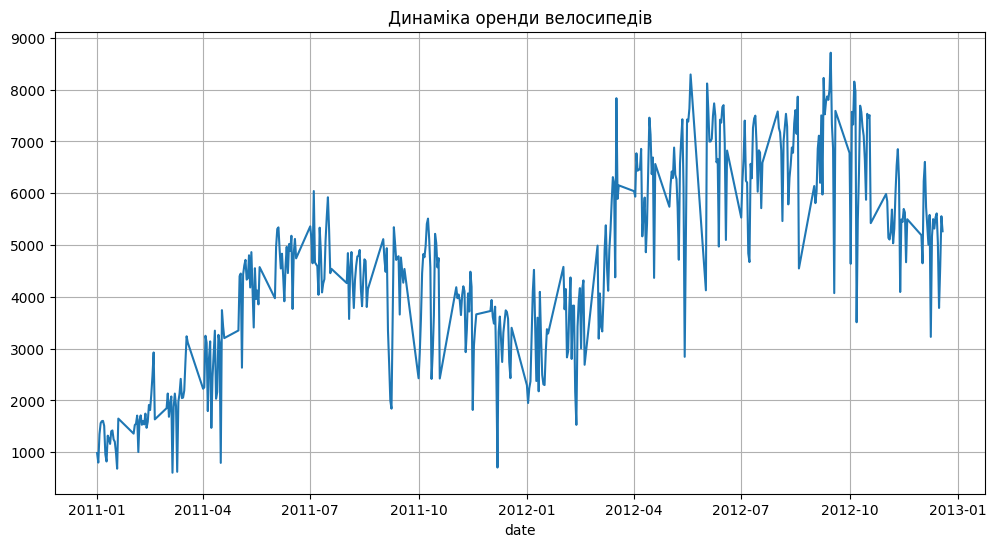

In [29]:
daily_rent.plot(
    figsize=(12,6),
    title='Динаміка оренди велосипедів',
    grid=True
    );

1. Заломи на графіку виникають через значні коливання кількості оренд, а також через неповноту даних. У наборі дані присутні лише за перші 19 днів кожного місяця, тому між 19-м числом і початком наступного місяця є пропуски. Для коректнішої візуалізації можна не з'єднувати точки через відсутні періоди або використовувати агрегацію даних за тижнями/місяцями.

In [47]:
df['day'].value_counts().sort_index()

,count
day,
1,575
2,573
3,573
4,574
5,575
6,572
7,574
8,574
9,575


2. Які загальні тенденції ви бачите на графіку?
На графіку видно загальну тенденцію до зростання кількості оренд велосипедів протягом досліджуваного періоду. У 2011 році кількість оренд переважно була нижчою, а у 2012 році значення стали значно вищими.
При цьому кількість оренд суттєво коливається від дня до дня, тобто немає стабільного плавного зростання.

3. Чи помітні якісь сезонні коливання?
Так, сезонність добре помітна.
взимку (12-02 місяць) кількість оренд нижча;
влітку з 03 місяця попит починає зростати;
в період Monsoon спостерігаються найвищі значення.
Це можна пояснити тим, що люди частіше користуються велосипедами в теплу та сприятливу погоду.

4. Чи є періоди з аномально високими або низькими значеннями і чому?

Спостерігається загальна тенденція до зростання кількості оренд від 2011 до 2012 року, але з великими щоденними коливаннями.

Так, помітна сезонність: найвищий попит спостерігається влітку та на початку осені, а найнижчий — взимку.

Є окремі аномально високі та низькі значення. Вони можуть бути пов'язані з погодними умовами, температурою, вітром, вихідними або святковими днями. Для точного визначення причин потрібно проаналізувати відповідні колонки.

In [54]:
daily_weather = df.groupby('date')[['temp', 'humidity', 'windspeed','count']].mean()

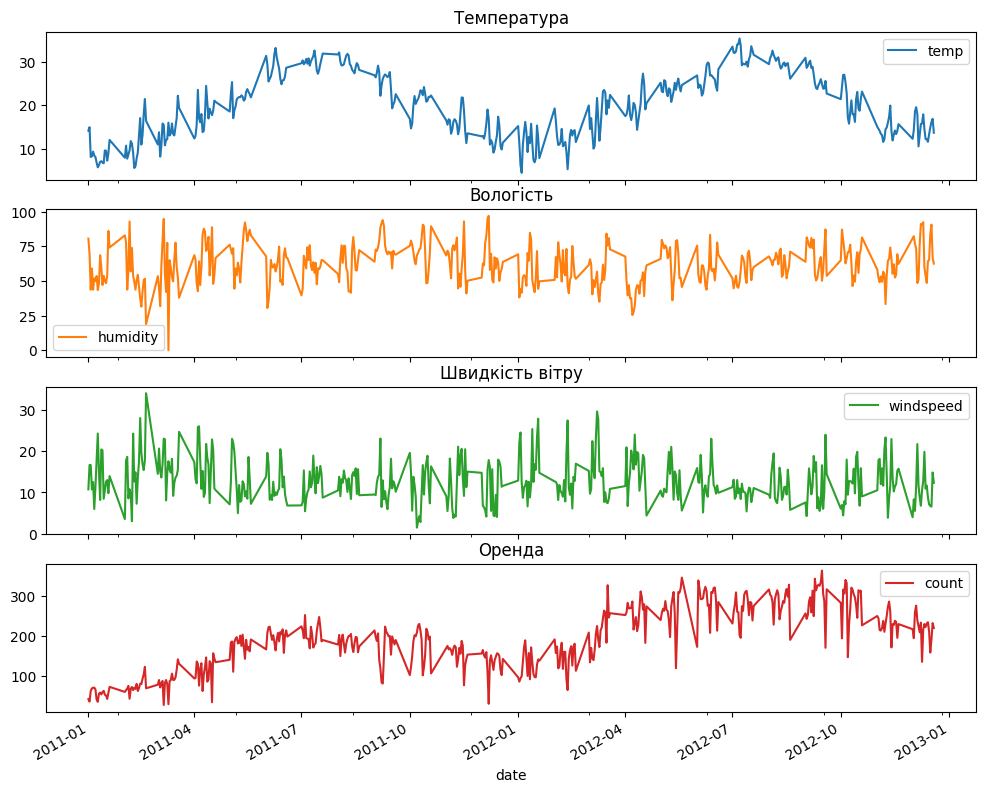

In [56]:
daily_weather.plot(
    subplots=True,
    figsize=(12, 10),
    title=['Температура', 'Вологість', 'Швидкість вітру', 'Оренда']
)

plt.show()


## Завдання 2: Аналіз сезонності (Bar Plot)

**Завдання:**
Побудуйте вертикальну стовпчасту діаграму середньої кількості орендованих велосипедів за сезонами(кварталами). Додайте підписи осей і заголовок.

Просунуте доповнення:
1. Позначте квартали не числом, а назвою на візуалізації.
2. Додайте підписи над стовпцями зі значеннями в кожному стовпці.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В який квартал найбільша середня кількість оренди велосипедів?
2. Як ви можете пояснити таку сезонну закономірність?
3. У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталми?

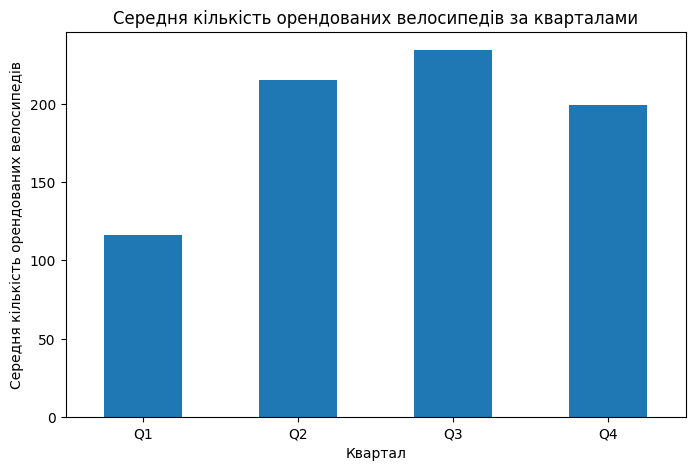

In [58]:

season_avg = df.groupby('season')['count'].mean()
season_avg.index = ['Q1', 'Q2', 'Q3', 'Q4']

ax = season_avg.plot(kind='bar',
                     figsize=(8, 5),
                     title='Середня кількість орендованих велосипедів за кварталами',
                     xlabel='Квартал',
                     ylabel='Середня кількість орендованих велосипедів',
                     rot=0,
                     )
plt.show()

1.В який квартал найбільша середня кількість оренди велосипедів? - Найбільша в 3 кварталі

2.Як ви можете пояснити таку сезонну закономірність? - Найсприятливіша погода


У скільки разів відрізняється оренда між найпопулярнішим та найменш популярним кварталами:

In [60]:
print(season_avg)

Q1    116.343261
Q2    215.251372
Q3    234.417124
Q4    198.988296
Name: count, dtype: float64


In [63]:

ratio = season_avg.loc['Q3'] / season_avg.loc['Q1']

print(f'У {ratio:.2f} рази')

У 2.01 рази


## Завдання 3: Динаміка за місяцями (Line Plot)

**Завдання:**
Створіть лінійний графік середньої кількості оренд велосипедів на годину по місяцях (тобто групування в рамках місяця і беремо середню кількість оренд у цей місяць з кількох років). Використайте маркери-кружечки для точок, додайте сітку та пофарбуйте лінію у червоний колір.

Просунуте доповнення:
- додайте аби по осі ОХ поділки були чітко на кожен окремий місяць по одній. Тобто сумарно 12 поділок.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які місяці спостерігається пік та спад оренди?
2. Чи збігається ця закономірність з результатами з попереднього завдання?
3. Як може вплинути клімат на оренду велосипедів протягом року?


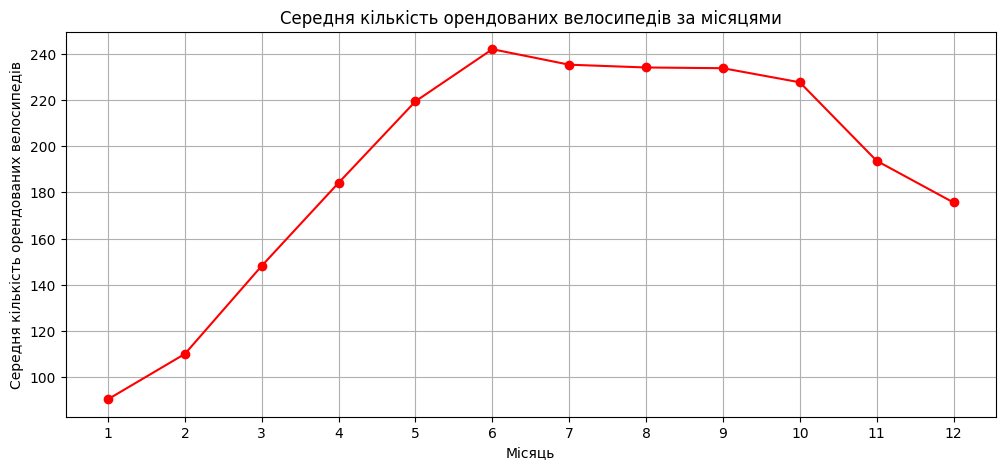

In [71]:
monthly_avg = df.groupby('month')['count'].mean()


monthly_avg.plot(
    kind='line',
    figsize=(12, 5),
    #monthly_avg.index,
    #monthly_avg.values,
    marker='o',
    color='red',
    grid=True,
    title='Середня кількість орендованих велосипедів за місяцями',
    xlabel='Місяць',
    ylabel='Середня кількість орендованих велосипедів'
)
plt.xticks(range(1, 13))
plt.show()

В які місяці спостерігається пік та спад оренди? - в 11-02 місяцях бачимо спад, зростає, починаючи з 03.

Чи збігається ця закономірність з результатами з попереднього завдання? - Так, так само і в поквартальних орендах.

Як може вплинути клімат на оренду велосипедів протягом року? - Так, дуже корелює з погодними умовами

## Завдання 4: Розподіл погодних умов (Pie Chart)

**Завдання:**
1. Побудуйте кругову діаграму з часткою записів за погодними умовами
2. Додайте підписи з відсотками та легенду з описами погоди (1=ясно, 2=туман, 3=легкий дощ, 4=сильний дощ).
3. Визначте свої відмінні від стандартних кольори для відображення кожної категорії.
4. Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. Яка погода переважає в датасеті?
2. Чи є дні із сильним дощем? Яка їх частка?
3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів?

Очікуваний результат:

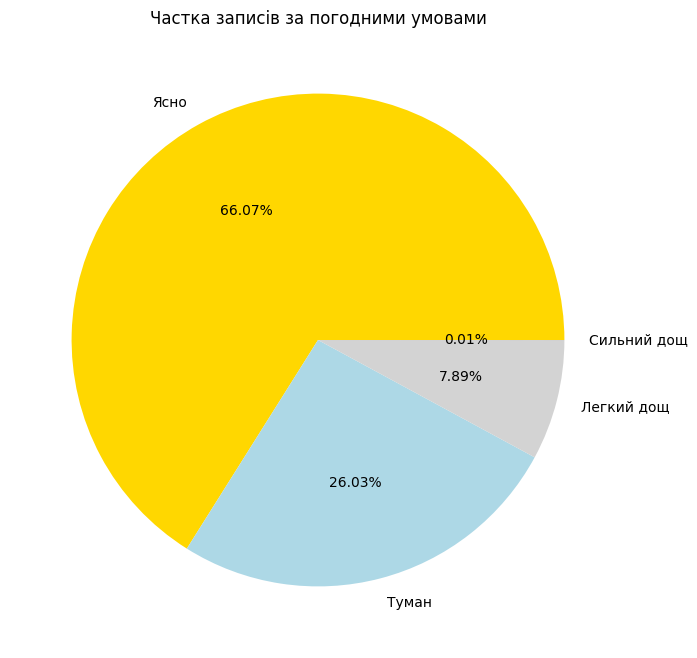

In [72]:
weather_rent = df.groupby('weather')['count'].sum()

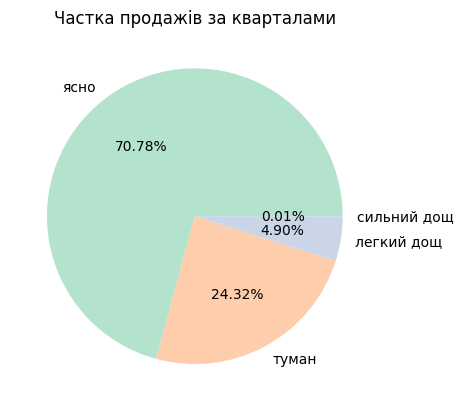

In [77]:
weather_rent.plot.pie(
    autopct='%1.2f%%',
    labels=['ясно', 'туман', 'легкий дощ', 'сильний дощ'],
    title='Частка продажів за кварталами',
    ylabel='',
    colors=plt.cm.Pastel2.colors
);


1. Яка погода переважає в датасеті? - В датасеті переважає сонячна погода

2. Чи є дні із сильним дощем? Яка їх частка? - Частка дні із сильним дощем 0,01%


In [82]:
rain_days = (df['weather'] == 4).sum()

print(f'Кількість днів із сильним дощем: {rain_days}')

Кількість днів із сильним дощем: 1



3. Як ви думаєте, як погодні умови впливають на попит на оренду велосипедів? - За ясної погоди попит зазвичай найвищий, оскільки людям комфортніше їздити на велосипеді. За туману та особливо дощу кількість оренд зменшується. Найсильніше падіння попиту, ймовірно, спостерігається під час сильного дощу, оскільки такі умови роблять поїздки менш комфортними та безпечними.

In [81]:
df.groupby('weather')['count'].sum()


,count
weather,
1,1476063
2,507160
3,102089
4,164


## Завдання 5: Box Plot для аналізу викидів

**Завдання:**
Створіть коробковий графік (box plot) кількості орендованих велосипедів для кожного типу погоди.

Просунуте доповнення:
- Використайте горизонтальну орієнтацію.
- Позначте погодні умови не числом, а назвою на візуалізації.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. При якій погоді найбільший розкид у кількості оренди?
2. Чи є викиди (outliers) в даних? При якій погоді?
3. При якій погоді медіанне значення оренди найвище?

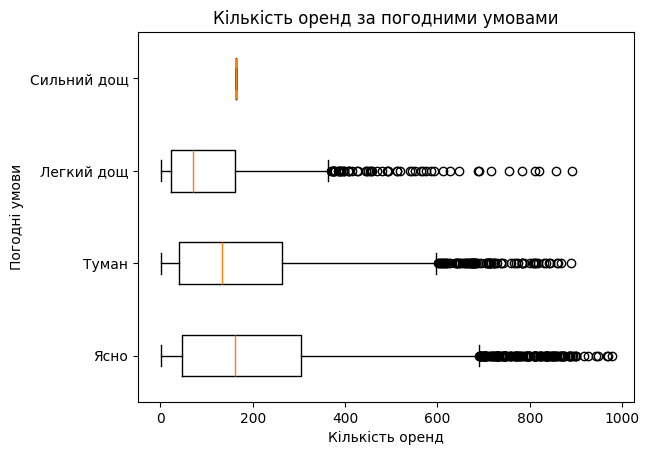

In [102]:
weather = pd.Categorical(
    df['weather'],
    categories=[1, 2, 3, 4],
    ordered=True
).rename_categories(
    ['Ясно', 'Туман', 'Легкий дощ', 'Сильний дощ']
)

data = [
    df[weather == 'Ясно']['count'],
    df[weather == 'Туман']['count'],
    df[weather == 'Легкий дощ']['count'],
    df[weather == 'Сильний дощ']['count']
]

plt.boxplot(data, vert=False)

plt.xlabel('Кількість оренд')
plt.ylabel('Погодні умови')
plt.yticks([1, 2, 3, 4], ['Ясно', 'Туман', 'Легкий дощ', 'Сильний дощ'])
plt.title('Кількість оренд за погодними умовами')

plt.show()

1. Найбільший розкид кількості оренд спостерігається за ясної погоди.
2. Викиди присутні за всіх погодних умов, найбільше — за ясної погоди та туману.
3. Найвище медіанне значення оренди спостерігається за ясної погоди.

## Завдання 6: Кореляція температури та оренди (Scatter Plot)

**Завдання:**
Побудуйте діаграму розсіювання залежності між температурою (`temp`) та загальною кількістю оренди (`count`). Розфарбуйте точки за сезонами, додайте напівпрозорість (alpha=0.6).

**Увага!** За замовченням буде колір

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
- Чи є зв'язок між температурою та кількістю оренди? Який?

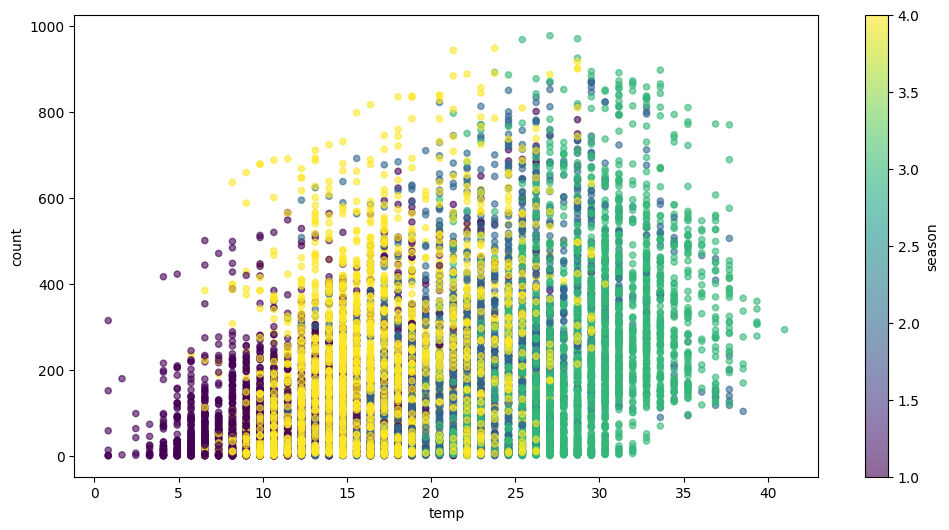

In [109]:
df.plot.scatter(
    x='temp',
    y='count',
    c='season',
    cmap='viridis',
    figsize=(12, 6),
    alpha=0.6
);

Між температурою та кількістю оренд спостерігається позитивний зв'язок: зі зростанням температури попит на оренду велосипедів загалом збільшується.

## (Опціонально) Завдання 7: Порівняння користувачів (Stacked Bar Chart)

**Завдання:**
Ми хочемо дізнатись як по дням тижня беруть в середньому в оренду велосипеди випадкові і зареєстровані користувачі.

Створіть стовпчасту діаграму з накопиченням (bar з налаштуванням `stacked=True`), яка показує співвідношення випадкових (`casual`) та зареєстрованих (`registered`) користувачів по днях тижня за кількістю взятих ними велосипедів в оренду в середньому. Використайте різні кольори для типів користувачів.

Дайте відповіді на питання нижче.

**Питання для інтерпретації:**
1. В які дні тижня більше оренд від зареєстрованих користувачів?
2. Як ви можете пояснити таку різницю в поведінці користувачів протягом тижня?

In [9]:
ordered_days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
df['weekday'] = pd.Categorical(df['weekday'], categories=ordered_days, ordered=True)


/tmp/ipykernel_494/3122142432.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  weekday_avg = df.groupby('weekday')[['casual', 'registered']].mean()


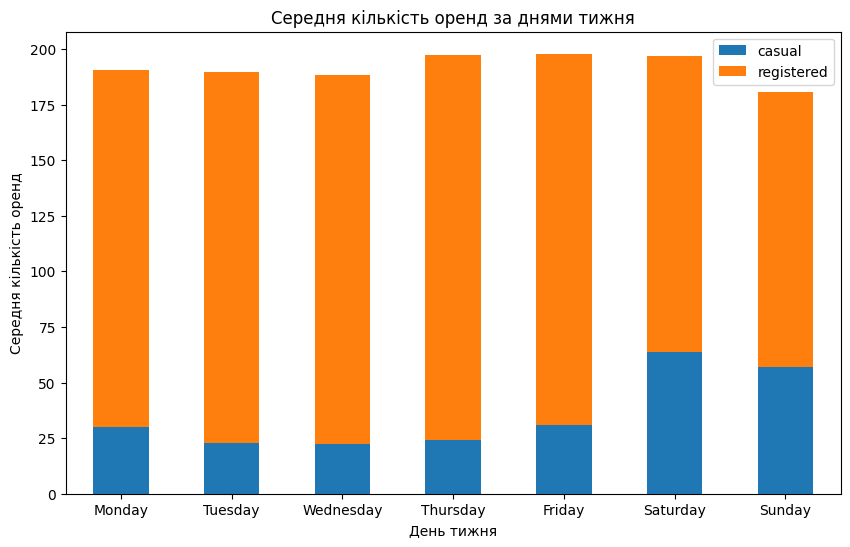

In [15]:
weekday_avg = df.groupby('weekday')[['casual', 'registered']].mean()

weekday_avg.plot.bar(
    stacked=True,
    figsize=(10, 6),
    xlabel='День тижня',
    ylabel='Середня кількість оренд',
    title='Середня кількість оренд за днями тижня'
)
plt.xticks(rotation=0)

plt.show()


1. Зареєстровані користувачі орендують частіше у всі дні тижня. Особливо помітна їхня перевага у будні дні.
2. Зареєстровані користувачі, ймовірно, використовують велосипеди регулярнодля поїздок на роботу або навчання, тому їхня активність стабільніша протягом робочого тижня.
Випадкові користувачі частіше орендують велосипеди для відпочинку, тому їхня частка може бути більшою у вихідні.